In [5]:
!pip -q install medmnist


train: 11959 images
Image shape: (11959, 28, 28, 3)
  basophil: 852
  eosinophil: 2181
  erythroblast: 1085
  immature granulocytes(myelocytes, metamyelocytes and promyelocytes): 2026
  lymphocyte: 849
  monocyte: 993
  neutrophil: 2330
  platelet: 1643

validation: 1712 images
Image shape: (1712, 28, 28, 3)
  basophil: 122
  eosinophil: 312
  erythroblast: 155
  immature granulocytes(myelocytes, metamyelocytes and promyelocytes): 290
  lymphocyte: 122
  monocyte: 143
  neutrophil: 333
  platelet: 235

test: 3421 images
Image shape: (3421, 28, 28, 3)
  basophil: 244
  eosinophil: 624
  erythroblast: 311
  immature granulocytes(myelocytes, metamyelocytes and promyelocytes): 579
  lymphocyte: 243
  monocyte: 284
  neutrophil: 666
  platelet: 470


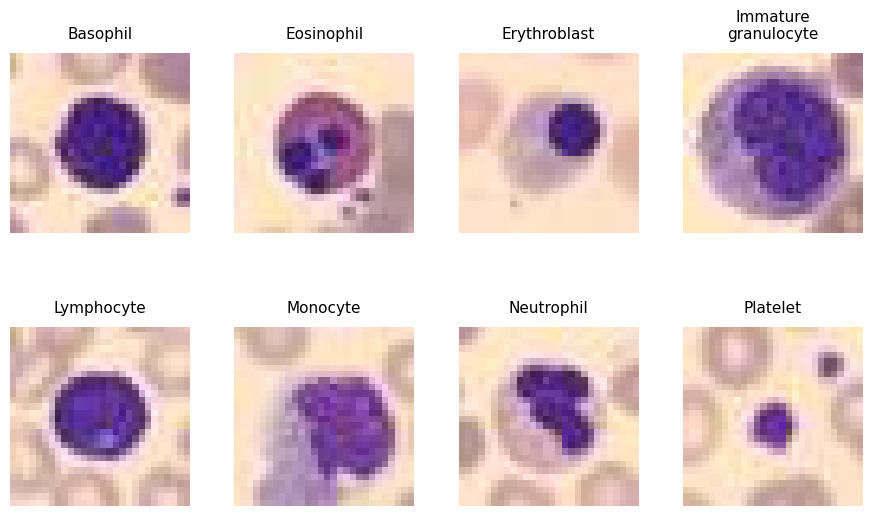

In [7]:

import numpy as np
import matplotlib.pyplot as plt
import medmnist
from medmnist import BloodMNIST

info = medmnist.INFO["bloodmnist"]
label_names = info["label"]

train_data = BloodMNIST(split="train", download=True)
val_data = BloodMNIST(split="val", download=True)
test_data = BloodMNIST(split="test", download=True)

datasets = {
    "train": train_data,
    "validation": val_data,
    "test": test_data
}

for split_name, dataset in datasets.items():
    labels = dataset.labels.reshape(-1).astype(int)
    counts = np.bincount(labels, minlength=8)

    print(f"\n{split_name}: {len(dataset)} images")
    print("Image shape:", dataset.imgs.shape)
    for class_id, count in enumerate(counts):
        print(f"  {label_names[str(class_id)]}: {count}")


display_names = [
    "Basophil",
    "Eosinophil",
    "Erythroblast",
    "Immature\ngranulocyte",
    "Lymphocyte",
    "Monocyte",
    "Neutrophil",
    "Platelet"
]

fig, axes = plt.subplots(2, 4, figsize=(11, 6))

shown = set()
for image, label in train_data:
    class_id = int(np.asarray(label).reshape(-1)[0])

    if class_id not in shown:
        ax = axes.flat[class_id]
        ax.imshow(image, interpolation="nearest")
        ax.set_title(display_names[class_id], fontsize=11, pad=10)
        ax.axis("off")
        shown.add(class_id)

    if len(shown) == 8:
        break

plt.subplots_adjust(wspace=0.25, hspace=0.45)

plt.savefig(
    "bloodmnist_samples_clean.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()


In [4]:
import torch
from torch.utils.data import DataLoader
from torchvision import transforms
from medmnist import BloodMNIST

# Convert images to PyTorch tensors and scale pixel values to [0, 1]
to_tensor = transforms.ToTensor()

train_data = BloodMNIST(
    split="train", transform=to_tensor, download=True
)
val_data = BloodMNIST(
    split="val", transform=to_tensor, download=True
)
test_data = BloodMNIST(
    split="test", transform=to_tensor, download=True
)

batch_size = 128

train_loader = DataLoader(
    train_data, batch_size=batch_size, shuffle=True, num_workers=2
)
val_loader = DataLoader(
    val_data, batch_size=batch_size, shuffle=False, num_workers=2
)
test_loader = DataLoader(
    test_data, batch_size=batch_size, shuffle=False, num_workers=2
)

# Check the shape and pixel range of one batch
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Pixel range:", images.min().item(), "to", images.max().item())
print("Device available:", "GPU" if torch.cuda.is_available() else "CPU")

Image batch shape: torch.Size([128, 3, 28, 28])
Label batch shape: torch.Size([128, 1])
Pixel range: 0.019607843831181526 to 1.0
Device available: CPU


In [5]:
import torch.nn as nn

num_classes = 8

class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3 * 28 * 28, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.network(x)


class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


# Check that each model returns eight class scores per image
mlp = MLP()
cnn = SmallCNN()

print("MLP output shape:", mlp(images).shape)
print("CNN output shape:", cnn(images).shape)

MLP output shape: torch.Size([128, 8])
CNN output shape: torch.Size([128, 8])


In [6]:
import random
import copy
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, f1_score


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)


def evaluate_model(model, data_loader, criterion):
    model.eval()
    total_loss = 0.0
    all_targets = []
    all_predictions = []

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.view(-1).long().to(device)

            logits = model(images)
            loss = criterion(logits, labels)

            total_loss += loss.item() * images.size(0)
            predictions = logits.argmax(dim=1)

            all_targets.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    average_loss = total_loss / len(data_loader.dataset)
    macro_f1 = f1_score(
        all_targets, all_predictions, average="macro", zero_division=0
    )
    accuracy = accuracy_score(all_targets, all_predictions)

    return average_loss, macro_f1, accuracy


def train_model(model, train_loader, val_loader, model_name,
                max_epochs=15, patience=4, learning_rate=1e-3):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
        weight_decay=1e-4
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_macro_f1": [],
        "val_accuracy": []
    }

    best_macro_f1 = -1.0
    best_epoch = 0
    best_state = copy.deepcopy(model.state_dict())
    epochs_without_improvement = 0

    for epoch in range(1, max_epochs + 1):
        model.train()
        total_train_loss = 0.0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.view(-1).long().to(device)

            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

            total_train_loss += loss.item() * images.size(0)

        train_loss = total_train_loss / len(train_loader.dataset)
        val_loss, val_macro_f1, val_accuracy = evaluate_model(
            model, val_loader, criterion
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_macro_f1"].append(val_macro_f1)
        history["val_accuracy"].append(val_accuracy)

        print(
            f"{model_name} | Epoch {epoch:02d} | "
            f"Train loss: {train_loss:.4f} | "
            f"Val loss: {val_loss:.4f} | "
            f"Val macro-F1: {val_macro_f1:.4f} | "
            f"Val accuracy: {val_accuracy:.4f}"
        )

        if val_macro_f1 > best_macro_f1:
            best_macro_f1 = val_macro_f1
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch}.")
            break

    model.load_state_dict(best_state)
    best_val_loss, best_val_macro_f1, best_val_accuracy = evaluate_model(
        model, val_loader, criterion
    )

    best_metrics = {
        "best_epoch": best_epoch,
        "val_loss": best_val_loss,
        "val_macro_f1": best_val_macro_f1,
        "val_accuracy": best_val_accuracy
    }

    print(
        f"\nBest {model_name}: "
        f"epoch={best_epoch}, "
        f"val macro-F1={best_val_macro_f1:.4f}, "
        f"val accuracy={best_val_accuracy:.4f}\n"
    )

    return model, history, best_metrics


# Train the MLP baseline
set_seed(42)
mlp_model, mlp_history, mlp_best = train_model(
    MLP(), train_loader, val_loader, model_name="MLP"
)

# Train the CNN without data augmentation
set_seed(42)
cnn_model, cnn_history, cnn_best = train_model(
    SmallCNN(), train_loader, val_loader, model_name="CNN"
)

Training device: cpu
MLP | Epoch 01 | Train loss: 1.5738 | Val loss: 1.1247 | Val macro-F1: 0.5142 | Val accuracy: 0.6343
MLP | Epoch 02 | Train loss: 1.1353 | Val loss: 0.8982 | Val macro-F1: 0.5783 | Val accuracy: 0.6665
MLP | Epoch 03 | Train loss: 0.9950 | Val loss: 0.8393 | Val macro-F1: 0.5873 | Val accuracy: 0.6758
MLP | Epoch 04 | Train loss: 0.9412 | Val loss: 0.8260 | Val macro-F1: 0.6144 | Val accuracy: 0.6852
MLP | Epoch 05 | Train loss: 0.9088 | Val loss: 0.7547 | Val macro-F1: 0.6709 | Val accuracy: 0.7155
MLP | Epoch 06 | Train loss: 0.8826 | Val loss: 0.7083 | Val macro-F1: 0.6797 | Val accuracy: 0.7407
MLP | Epoch 07 | Train loss: 0.8573 | Val loss: 0.7917 | Val macro-F1: 0.6025 | Val accuracy: 0.6706
MLP | Epoch 08 | Train loss: 0.8276 | Val loss: 0.6701 | Val macro-F1: 0.7260 | Val accuracy: 0.7611
MLP | Epoch 09 | Train loss: 0.8244 | Val loss: 0.6738 | Val macro-F1: 0.6913 | Val accuracy: 0.7465
MLP | Epoch 10 | Train loss: 0.8058 | Val loss: 0.7224 | Val macro-F1:

In [7]:
from torchvision import transforms
from torch.utils.data import DataLoader
from medmnist import BloodMNIST

# Apply mild spatial augmentation to training images only
train_aug_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor()
])

train_aug_data = BloodMNIST(
    split="train",
    transform=train_aug_transform,
    download=False
)

train_aug_loader = DataLoader(
    train_aug_data,
    batch_size=128,
    shuffle=True,
    num_workers=2
)

# Keep the validation images unchanged
set_seed(42)
cnn_aug_model, cnn_aug_history, cnn_aug_best = train_model(
    SmallCNN(),
    train_aug_loader,
    val_loader,
    model_name="CNN with augmentation"
)

CNN with augmentation | Epoch 01 | Train loss: 0.9719 | Val loss: 0.6548 | Val macro-F1: 0.7348 | Val accuracy: 0.7845
CNN with augmentation | Epoch 02 | Train loss: 0.4890 | Val loss: 0.6382 | Val macro-F1: 0.6883 | Val accuracy: 0.7629
CNN with augmentation | Epoch 03 | Train loss: 0.4007 | Val loss: 0.4164 | Val macro-F1: 0.7864 | Val accuracy: 0.8382
CNN with augmentation | Epoch 04 | Train loss: 0.3429 | Val loss: 0.4792 | Val macro-F1: 0.8312 | Val accuracy: 0.8335
CNN with augmentation | Epoch 05 | Train loss: 0.3145 | Val loss: 0.6562 | Val macro-F1: 0.7093 | Val accuracy: 0.7827
CNN with augmentation | Epoch 06 | Train loss: 0.2982 | Val loss: 0.3894 | Val macro-F1: 0.8286 | Val accuracy: 0.8662
CNN with augmentation | Epoch 07 | Train loss: 0.2761 | Val loss: 0.2345 | Val macro-F1: 0.9170 | Val accuracy: 0.9276
CNN with augmentation | Epoch 08 | Train loss: 0.2643 | Val loss: 0.4508 | Val macro-F1: 0.7595 | Val accuracy: 0.8300
CNN with augmentation | Epoch 09 | Train loss: 0

In [8]:
import contextlib
import io

# Keep the current seed-42 models and validation results
model_runs = {
    "MLP": [mlp_model],
    "CNN": [cnn_model],
    "CNN with augmentation": [cnn_aug_model]
}

metric_runs = {
    "MLP": [mlp_best],
    "CNN": [cnn_best],
    "CNN with augmentation": [cnn_aug_best]
}


def run_quietly(model, train_loader_for_run, model_name, seed):
    set_seed(seed)

    # Suppress per-epoch output and keep the final summary only
    with contextlib.redirect_stdout(io.StringIO()):
        trained_model, _, best_metrics = train_model(
            model,
            train_loader_for_run,
            val_loader,
            model_name=model_name,
            max_epochs=15,
            patience=4,
            learning_rate=1e-3
        )

    print(
        f"{model_name}, seed={seed}: "
        f"best epoch={best_metrics['best_epoch']}, "
        f"val macro-F1={best_metrics['val_macro_f1']:.4f}, "
        f"val accuracy={best_metrics['val_accuracy']:.4f}"
    )

    return trained_model, best_metrics


# Repeat each model with two additional random seeds
for seed in [7, 21]:
    model, metrics = run_quietly(MLP(), train_loader, "MLP", seed)
    model_runs["MLP"].append(model)
    metric_runs["MLP"].append(metrics)

    model, metrics = run_quietly(SmallCNN(), train_loader, "CNN", seed)
    model_runs["CNN"].append(model)
    metric_runs["CNN"].append(metrics)

    model, metrics = run_quietly(
        SmallCNN(), train_aug_loader, "CNN with augmentation", seed
    )
    model_runs["CNN with augmentation"].append(model)
    metric_runs["CNN with augmentation"].append(metrics)


# Summarize validation performance across the three seeds
for model_name, runs in metric_runs.items():
    f1_scores = np.array([run["val_macro_f1"] for run in runs])
    accuracies = np.array([run["val_accuracy"] for run in runs])

    print(
        f"{model_name}: "
        f"Macro-F1 = {f1_scores.mean():.4f} ± {f1_scores.std(ddof=1):.4f}, "
        f"Accuracy = {accuracies.mean():.4f} ± {accuracies.std(ddof=1):.4f}"
    )

MLP, seed=7: best epoch=11, val macro-F1=0.7275, val accuracy=0.7704
CNN, seed=7: best epoch=6, val macro-F1=0.9113, val accuracy=0.9200
CNN with augmentation, seed=7: best epoch=4, val macro-F1=0.8444, val accuracy=0.8639
MLP, seed=21: best epoch=6, val macro-F1=0.6700, val accuracy=0.7150
CNN, seed=21: best epoch=2, val macro-F1=0.8263, val accuracy=0.8528
CNN with augmentation, seed=21: best epoch=8, val macro-F1=0.9092, val accuracy=0.9176
MLP: Macro-F1 = 0.7078 ± 0.0327, Accuracy = 0.7488 ± 0.0297
CNN: Macro-F1 = 0.8678 ± 0.0425, Accuracy = 0.8865 ± 0.0336
CNN with augmentation: Macro-F1 = 0.8902 ± 0.0399, Accuracy = 0.9030 ± 0.0343


In [9]:
import numpy as np
import torch
from sklearn.metrics import accuracy_score, f1_score


def get_predictions(model, data_loader):
    model.eval()
    all_targets = []
    all_predictions = []

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.view(-1).long().to(device)

            logits = model(images)
            predictions = logits.argmax(dim=1)

            all_targets.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    return np.array(all_targets), np.array(all_predictions)


test_results = {}

# Evaluate each pre-specified model on the held-out test set
for model_name, models in model_runs.items():
    test_results[model_name] = []

    for seed_index, model in enumerate(models):
        y_true, y_pred = get_predictions(model, test_loader)

        metrics = {
            "macro_f1": f1_score(
                y_true, y_pred, average="macro", zero_division=0
            ),
            "accuracy": accuracy_score(y_true, y_pred)
        }
        test_results[model_name].append(metrics)

        print(
            f"{model_name} | run {seed_index + 1} | "
            f"Test macro-F1: {metrics['macro_f1']:.4f} | "
            f"Test accuracy: {metrics['accuracy']:.4f}"
        )

# Summarize test performance across the three runs
print("\nTest summary across runs:")
for model_name, runs in test_results.items():
    macro_f1_scores = np.array([run["macro_f1"] for run in runs])
    accuracies = np.array([run["accuracy"] for run in runs])

    print(
        f"{model_name}: "
        f"Macro-F1 = {macro_f1_scores.mean():.4f} "
        f"± {macro_f1_scores.std(ddof=1):.4f}, "
        f"Accuracy = {accuracies.mean():.4f} "
        f"± {accuracies.std(ddof=1):.4f}"
    )

MLP | run 1 | Test macro-F1: 0.7025 | Test accuracy: 0.7401
MLP | run 2 | Test macro-F1: 0.7083 | Test accuracy: 0.7524
MLP | run 3 | Test macro-F1: 0.6458 | Test accuracy: 0.6957
CNN | run 1 | Test macro-F1: 0.8550 | Test accuracy: 0.8758
CNN | run 2 | Test macro-F1: 0.8965 | Test accuracy: 0.9088
CNN | run 3 | Test macro-F1: 0.8218 | Test accuracy: 0.8445
CNN with augmentation | run 1 | Test macro-F1: 0.9050 | Test accuracy: 0.9158
CNN with augmentation | run 2 | Test macro-F1: 0.8548 | Test accuracy: 0.8731
CNN with augmentation | run 3 | Test macro-F1: 0.9031 | Test accuracy: 0.9126

Test summary across runs:
MLP: Macro-F1 = 0.6855 ± 0.0345, Accuracy = 0.7294 ± 0.0298
CNN: Macro-F1 = 0.8577 ± 0.0374, Accuracy = 0.8764 ± 0.0322
CNN with augmentation: Macro-F1 = 0.8876 ± 0.0285, Accuracy = 0.9005 ± 0.0238



CNN average recall by class:
Basophil: 0.757
Eosinophil: 0.924
Erythroblast: 0.829
Immature granulocyte: 0.729
Lymphocyte: 0.881
Monocyte: 0.825
Neutrophil: 0.959
Platelet: 1.000

CNN with augmentation average recall by class:
Basophil: 0.801
Eosinophil: 0.975
Erythroblast: 0.932
Immature granulocyte: 0.837
Lymphocyte: 0.846
Monocyte: 0.772
Neutrophil: 0.911
Platelet: 1.000


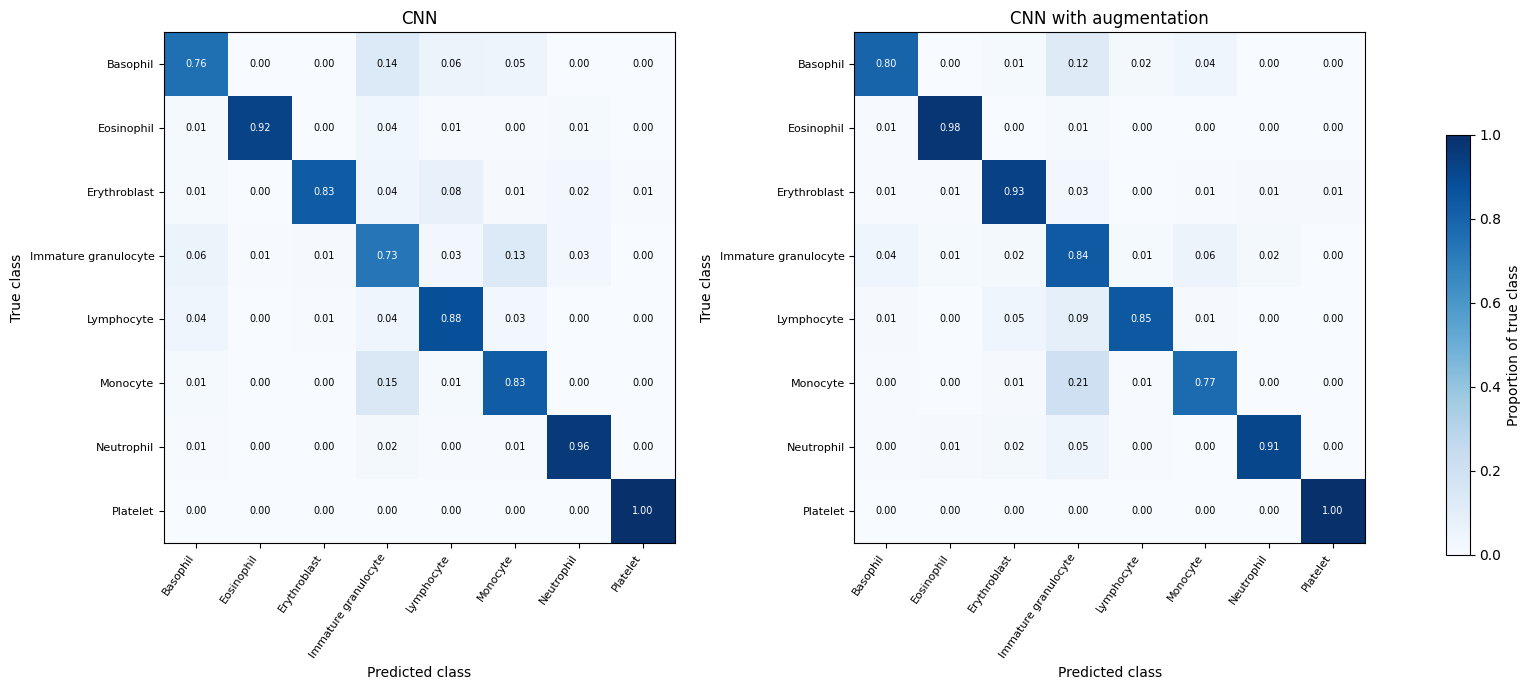

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

class_names = [
    "Basophil",
    "Eosinophil",
    "Erythroblast",
    "Immature granulocyte",
    "Lymphocyte",
    "Monocyte",
    "Neutrophil",
    "Platelet"
]

model_names = ["CNN", "CNN with augmentation"]
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, model_name in zip(axes, model_names):
    normalized_matrices = []

    for model in model_runs[model_name]:
        y_true, y_pred = get_predictions(model, test_loader)

        matrix = confusion_matrix(
            y_true,
            y_pred,
            labels=np.arange(8),
            normalize="true"
        )
        normalized_matrices.append(matrix)

    average_matrix = np.mean(normalized_matrices, axis=0)

    image = ax.imshow(average_matrix, cmap="Blues", vmin=0, vmax=1)
    ax.set_title(model_name)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.set_xticks(np.arange(8))
    ax.set_yticks(np.arange(8))
    ax.set_xticklabels(class_names, rotation=55, ha="right", fontsize=8)
    ax.set_yticklabels(class_names, fontsize=8)

    for row in range(8):
        for col in range(8):
            ax.text(
                col, row, f"{average_matrix[row, col]:.2f}",
                ha="center", va="center",
                color="white" if average_matrix[row, col] > 0.55 else "black",
                fontsize=7
            )

    recalls = np.diag(average_matrix)
    print(f"\n{model_name} average recall by class:")
    for class_name, recall in zip(class_names, recalls):
        print(f"{class_name}: {recall:.3f}")

# Reserve space on the right for the colorbar
fig.tight_layout(rect=[0, 0, 0.88, 1])

# Place the colorbar at the far right of the figure
colorbar_ax = fig.add_axes([0.91, 0.20, 0.015, 0.60])
fig.colorbar(
    image,
    cax=colorbar_ax,
    label="Proportion of true class"
)